

**Name:** Bhushan Hiralal Patel

**track:** Data Science

**task 3:** Car Price Prediction with Machine Learning

**Objective:**

The objective of this project is to analyze used car data and develop a machine learning model to predict car selling prices based on various factors such as car brand, manufacturing year, fuel type, transmission, mileage, engine capacity, and kilometres driven. Linear Regression and Random Forest algorithms are used to train and evaluate the prediction models.

In [ ]:
from google.colab import files

uploaded = files.upload()


Saving Car details v3.csv to Car details v3.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('Car details v3.csv')

# Display first 5 rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [ ]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (8128, 13)

Column Names:
Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          790

In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check percentage of missing values
print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df)) * 100)

Missing Values:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

Duplicate Records:
1202

Missing Value Percentage:
name             0.000000
year             0.000000
selling_price    0.000000
km_driven        0.000000
fuel             0.000000
seller_type      0.000000
transmission     0.000000
owner            0.000000
mileage          2.718996
engine           2.718996
max_power        2.645177
torque           2.731299
seats            2.718996
dtype: float64


In [ ]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove rows containing missing values
df = df.dropna()

# Check dataset after cleaning
print("Dataset Shape after Cleaning:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape after Cleaning: (6717, 13)

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           0
seats            0
dtype: int64

Duplicate Records:
0


In [ ]:
# Display statistical summary
df.describe()

,year,selling_price,km_driven,seats
count,6717.000000,6.717000e+03,6.717000e+03,6717.000000
mean,2013.611136,5.263860e+05,7.339834e+04,5.434271
std,3.897402,5.235504e+05,5.870328e+04,0.983805
min,1994.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.500000e+05,3.800000e+04,5.000000
50%,2014.000000,4.200000e+05,6.820300e+04,5.000000
75%,2017.000000,6.500000e+05,1.000000e+05,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


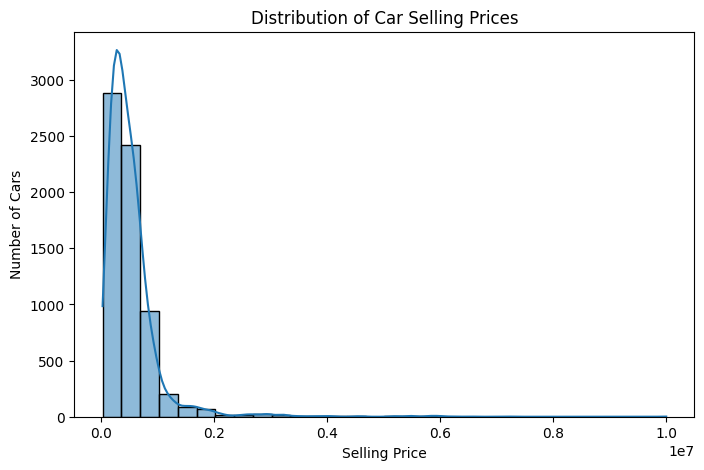

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df['selling_price'], bins=30, kde=True)

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')

plt.show()

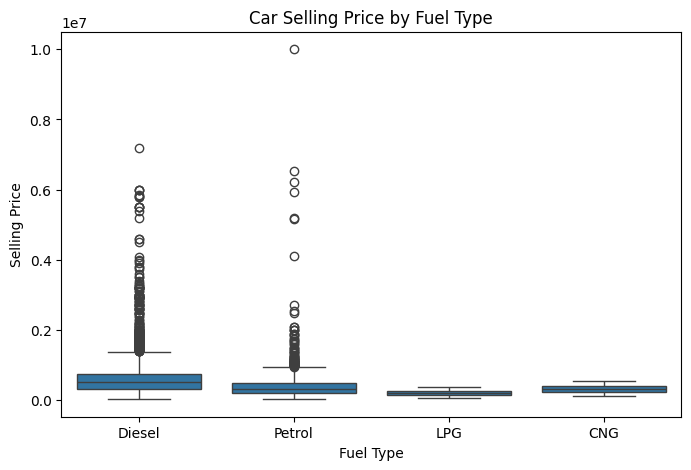

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='fuel', y='selling_price', data=df)

plt.title('Car Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')

plt.show()

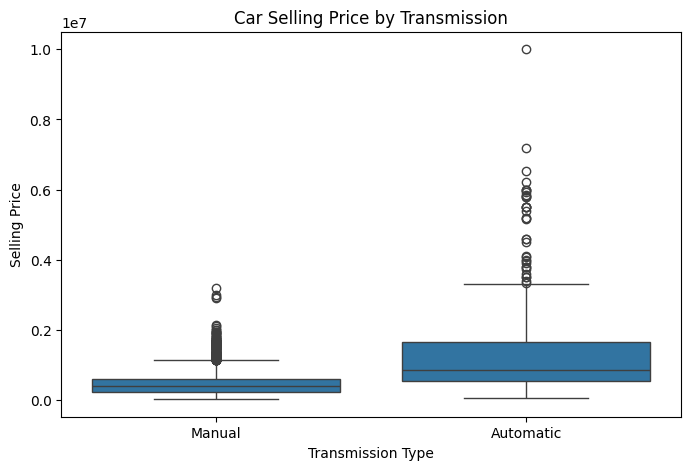

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='transmission', y='selling_price', data=df)

plt.title('Car Selling Price by Transmission')
plt.xlabel('Transmission Type')
plt.ylabel('Selling Price')

plt.show()

In [ ]:
# Create car age column
df['car_age'] = 2026 - df['year']

# Display updated dataset
df[['name', 'year', 'car_age', 'selling_price']].head()

,name,year,car_age,selling_price
0,Maruti Swift Dzire VDI,2014,12,450000
1,Skoda Rapid 1.5 TDI Ambition,2014,12,370000
2,Honda City 2017-2020 EXi,2006,20,158000
3,Hyundai i20 Sportz Diesel,2010,16,225000
4,Maruti Swift VXI BSIII,2007,19,130000


In [ ]:
# Extract car brand
df['brand'] = df['name'].str.split().str[0]

# Display car brands
print(df[['name', 'brand']].head(10))

                                   name    brand
0                Maruti Swift Dzire VDI   Maruti
1          Skoda Rapid 1.5 TDI Ambition    Skoda
2              Honda City 2017-2020 EXi    Honda
3             Hyundai i20 Sportz Diesel  Hyundai
4                Maruti Swift VXI BSIII   Maruti
5         Hyundai Xcent 1.2 VTVT E Plus  Hyundai
6          Maruti Wagon R LXI DUO BSIII   Maruti
7                    Maruti 800 DX BSII   Maruti
8                      Toyota Etios VXD   Toyota
9  Ford Figo Diesel Celebration Edition     Ford


In [ ]:
print("Updated Dataset Shape:", df.shape)

print("\nUpdated Columns:")
print(df.columns.tolist())

Updated Dataset Shape: (6717, 15)

Updated Columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'car_age', 'brand']


In [ ]:
# Identify categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Categorical Columns:")
print(categorical_columns)

Categorical Columns:
Index(['name', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage',
       'engine', 'max_power', 'torque', 'brand'],
      dtype='object')


In [ ]:
# Convert categorical data into numerical data
df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Original Dataset Shape:", df.shape)
print("Encoded Dataset Shape:", df_encoded.shape)

df_encoded.head()

Original Dataset Shape: (6717, 15)
Encoded Dataset Shape: (6717, 3297)


,year,selling_price,km_driven,seats,car_age,name_Ambassador Classic 2000 DSZ AC PS,name_Ambassador Grand 1500 DSZ BSIII,name_Ambassador Grand 2000 DSZ PW CL,name_Ashok Leyland Stile LE,name_Audi A3 35 TDI Premium Plus,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,2014,450000,145500,5.0,12,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2014,370000,120000,5.0,12,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,2006,158000,140000,5.0,20,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2010,225000,127000,5.0,16,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2007,130000,120000,5.0,19,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
print(df_encoded.dtypes)

year                  int64
selling_price         int64
km_driven             int64
seats               float64
car_age               int64
                     ...   
brand_Skoda           int64
brand_Tata            int64
brand_Toyota          int64
brand_Volkswagen      int64
brand_Volvo           int64
Length: 3297, dtype: object


In [ ]:
# Make a copy of the cleaned dataset
model_df = df.copy()

# Extract numerical values from columns containing units
for col in ['mileage', 'engine', 'max_power']:
    model_df[col] = pd.to_numeric(
        model_df[col].astype(str).str.extract(r'(\d+\.?\d*)')[0],
        errors='coerce'
    )

# Remove rows with any new missing values
model_df = model_df.dropna()

# Remove columns that are not needed
model_df = model_df.drop(columns=['name', 'torque'])

# Convert categorical columns into numerical values
model_df = pd.get_dummies(
    model_df,
    drop_first=True,
    dtype=int
)

print("Final Dataset Shape:", model_df.shape)
model_df.head()

Final Dataset Shape: (6717, 48)


,year,selling_price,km_driven,mileage,engine,max_power,seats,car_age,fuel_Diesel,fuel_LPG,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,2014,450000,145500,23.40,1248,74.00,5.0,12,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2014,370000,120000,21.14,1498,103.52,5.0,12,1,0,...,0,0,0,0,0,1,0,0,0,0
2,2006,158000,140000,17.70,1497,78.00,5.0,20,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2010,225000,127000,23.00,1396,90.00,5.0,16,1,0,...,0,0,0,0,0,0,0,0,0,0
4,2007,130000,120000,16.10,1298,88.20,5.0,19,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Independent variables
X = model_df.drop('selling_price', axis=1)

# Dependent variable
y = model_df['selling_price']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (6717, 47)
Target Shape: (6717,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5373, 47)
Testing Data: (1344, 47)


In [ ]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [ ]:
# Predict car prices
lr_predictions = lr_model.predict(X_test)

# Display actual and predicted prices
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': lr_predictions
})

comparison.head(10)

,Actual Price,Predicted Price
0,450000,1.037874e+06
1,800000,7.594568e+05
2,75000,1.556424e+05
3,3200000,1.681757e+06
4,1650000,1.844913e+06
5,180000,4.791207e+03
6,1019999,9.079751e+05
7,350000,4.359408e+05
8,722000,7.359053e+05
9,315000,3.585754e+05


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, lr_predictions)
rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("--------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
--------------------------
MAE: 131565.98209448296
RMSE: 238059.71730688037
R2 Score: 0.7417298049674657


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [ ]:
# Predict car prices
rf_predictions = rf_model.predict(X_test)

# Display actual and predicted prices
rf_comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': rf_predictions
})

rf_comparison.head(10)

,Actual Price,Predicted Price
0,450000,1.544450e+06
1,800000,7.214200e+05
2,75000,2.388367e+05
3,3200000,3.024200e+06
4,1650000,1.664410e+06
5,180000,1.351950e+05
6,1019999,1.003118e+06
7,350000,3.801500e+05
8,722000,8.222192e+05
9,315000,2.658575e+05


In [ ]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Results
---------------------
MAE: 73940.34537306016
RMSE: 124058.8630721093
R2 Score: 0.9298612443006797


In [ ]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae, rf_mae],
    'RMSE': [rmse, rf_rmse],
    'R2 Score': [r2, rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,131565.982094,238059.717307,0.741730
1,Random Forest,73940.345373,124058.863072,0.929861


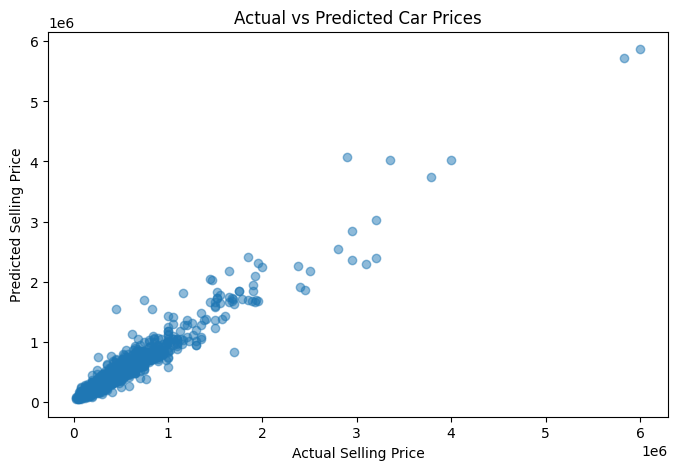

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_predictions, alpha=0.5)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

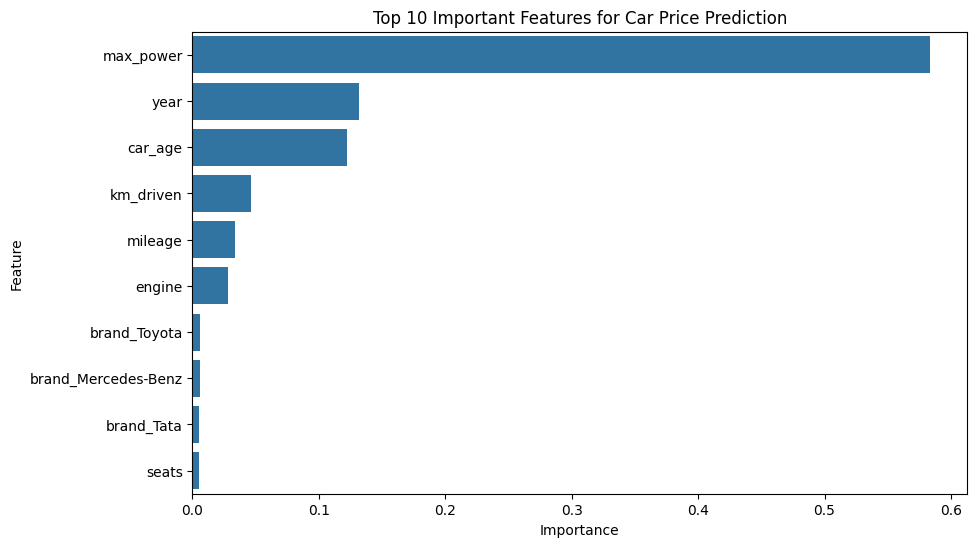

In [ ]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features for Car Price Prediction")
plt.show()

In [ ]:
import joblib

joblib.dump(rf_model, 'car_price_prediction_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download('car_price_prediction_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>